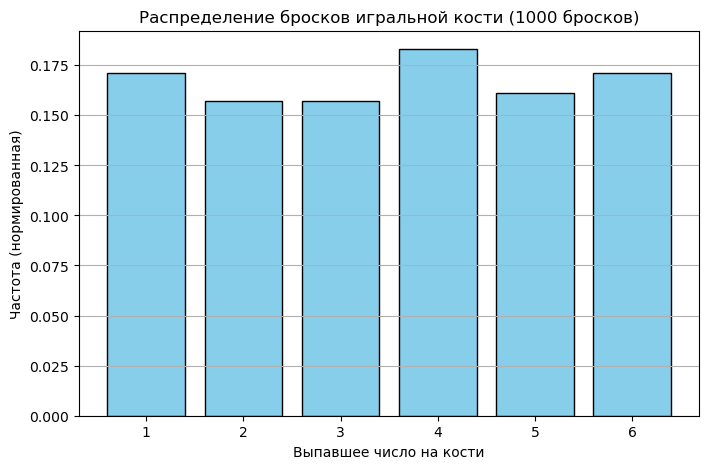

In [1]:
# Задача 1:
 - 1. Сгенерируйте список из 1000 случайных чисел в диапазоне от 1 до 6, имитируя броски игральной кости.
 - 2. Используйте plt.hist для визуализации распределения чисел.
 - 3. Настройте параметры bins, rwidth, и density, чтобы гистограмма корректно отображала равномерное распределение.
 - 4. Добавьте подписи к осям и заголовок гистограммы.


import numpy as np
import matplotlib.pyplot as plt

# 1. Генерация 1000 бросков кости
np.random.seed(0)
dice_rolls = np.random.randint(1, 7, size=1000)

# 2. Построение гистограммы
plt.figure(figsize=(8, 5))
plt.hist(dice_rolls, bins=np.arange(1, 8) - 0.5, rwidth=0.8, density=True, color='skyblue', edgecolor='black')

# 3. Настройка осей и заголовка
plt.xticks(range(1, 7))
plt.xlabel('Выпавшее число на кости')
plt.ylabel('Частота (нормированная)')
plt.title('Распределение бросков игральной кости (1000 бросков)')
plt.grid(axis='y')
plt.show()


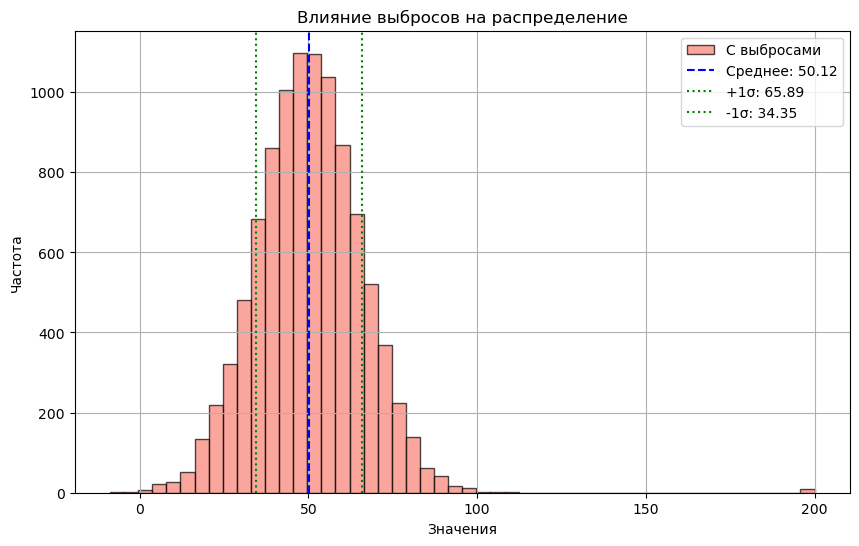

Исходное среднее: 49.97, стандартное отклонение: 15.05
С выбросами среднее: 50.12, стандартное отклонение: 15.77


In [2]:
# Задача 2: Исследовать, как выбросы влияют на характеристики нормального распределения (среднее значение и стандартное отклонение), и визуализировать эффект выбросов на гистограмме распределения.
 - 1. Используйте np.random.seed() для установки начального значения генератора случайных чисел для воспроизводимости результатов.
 - 2. Сгенерируйте выборку из 10000 значений, следующих нормальному распределению с заданным средним (например, 50) и стандартным отклонением (например, 15), используя np.random.normal().
 - 3. Добавьте к этой выборке несколько выбросов — значений, сильно отличающихся от остальных (например, 10 значений в районе 200).
 - 4. Рассчитайте новые среднее значение и стандартное отклонение для модифицированной выборки.
 - 5. Визуализируйте модифицированное распределение с помощью plt.hist(), отметьте новое среднее значение и стандартные отклонения, как в предыдущем примере.
 - 6. Сравните графики и числовые характеристики исходного и модифицированного распределений, чтобы обсудить влияние выбросов на распределение.

# 1. Установка зерна генератора
np.random.seed(42)

# 2. Исходное нормальное распределение
normal_data = np.random.normal(loc=50, scale=15, size=10000)

# 3. Добавим выбросы
outliers = np.full(10, 200)  # 10 выбросов значением 200
modified_data = np.concatenate([normal_data, outliers])

# 4. Расчет характеристик
mean_original = np.mean(normal_data)
std_original = np.std(normal_data)

mean_modified = np.mean(modified_data)
std_modified = np.std(modified_data)

# 5. Визуализация
plt.figure(figsize=(10, 6))
plt.hist(modified_data, bins=50, color='salmon', edgecolor='black', alpha=0.7, label='С выбросами')

# Отметим среднее и стандартные отклонения
plt.axvline(mean_modified, color='blue', linestyle='--', label=f'Среднее: {mean_modified:.2f}')
plt.axvline(mean_modified + std_modified, color='green', linestyle=':', label=f'+1σ: {mean_modified + std_modified:.2f}')
plt.axvline(mean_modified - std_modified, color='green', linestyle=':', label=f'-1σ: {mean_modified - std_modified:.2f}')

plt.title('Влияние выбросов на распределение')
plt.xlabel('Значения')
plt.ylabel('Частота')
plt.legend()
plt.grid(True)
plt.show()

# 6. Сравнение
print(f'Исходное среднее: {mean_original:.2f}, стандартное отклонение: {std_original:.2f}')
print(f'С выбросами среднее: {mean_modified:.2f}, стандартное отклонение: {std_modified:.2f}')


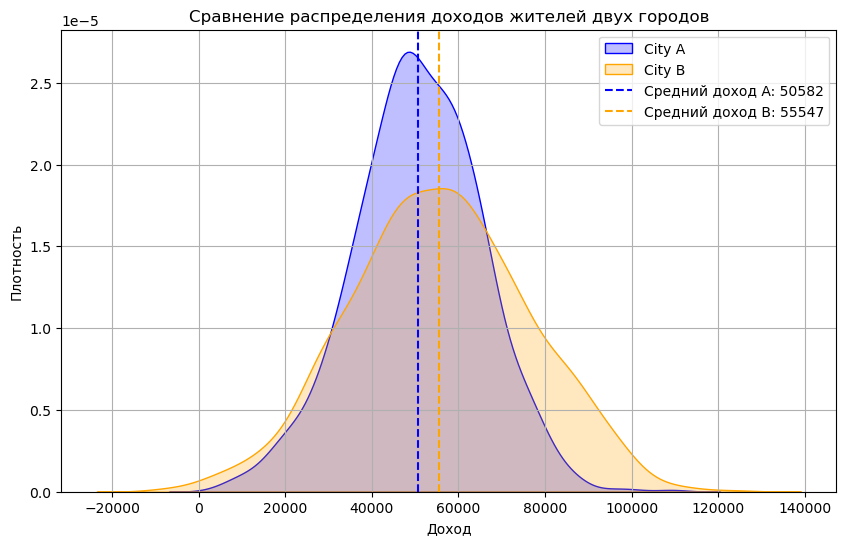

In [3]:
# Задача 3: Используйте KDE для анализа и сравнения распределения доходов жителей двух разных городов.
 - 1. Сгенерируйте две выборки данных, представляющие собой доходы жителей двух городов: CityA и CityB. Для CityA используйте нормальное распределение с параметрами среднего дохода 50000 и стандартного отклонения 15000. Для CityB используйте нормальное распределение с параметрами среднего дохода 55000 и стандартного отклонения 20000. В каждой выборке должно быть по 1000 значений.
 - 2. Визуализируйте распределения доходов для каждого города с помощью sns.kdeplot, отобразив оба распределения на одном графике для наглядного сравнения.
 - 3. Добавьте на график вертикальные линии, указывающие средний доход для каждого города.
 - 4. Добавьте заголовок, подписи к осям, а также легенду, чтобы указать, какой цвет соответствует каждому городу.

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Генерация данных
np.random.seed(1)
cityA_income = np.random.normal(50000, 15000, 1000)
cityB_income = np.random.normal(55000, 20000, 1000)

# 2. KDE-график
plt.figure(figsize=(10, 6))
sns.kdeplot(cityA_income, label='City A', shade=True, color='blue')
sns.kdeplot(cityB_income, label='City B', shade=True, color='orange')

# 3. Вертикальные линии среднего
plt.axvline(np.mean(cityA_income), color='blue', linestyle='--', label=f'Средний доход A: {np.mean(cityA_income):.0f}')
plt.axvline(np.mean(cityB_income), color='orange', linestyle='--', label=f'Средний доход B: {np.mean(cityB_income):.0f}')

# 4. Подписи
plt.title('Сравнение распределения доходов жителей двух городов')
plt.xlabel('Доход')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True)
plt.show()


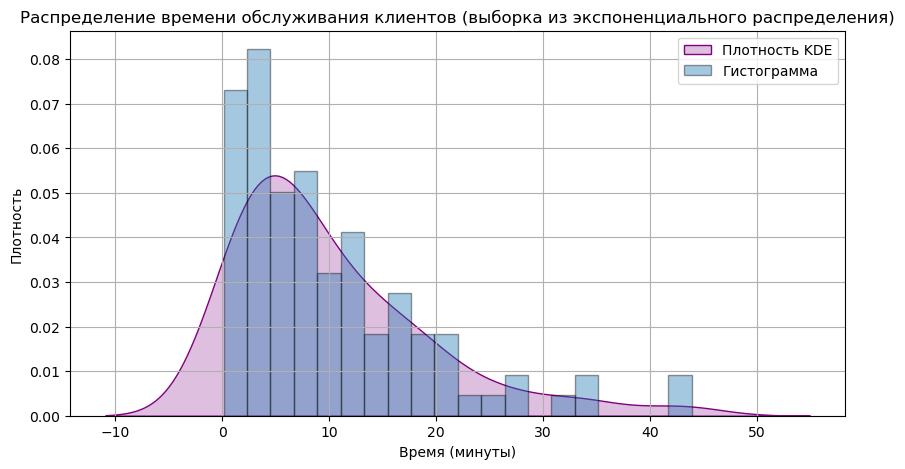

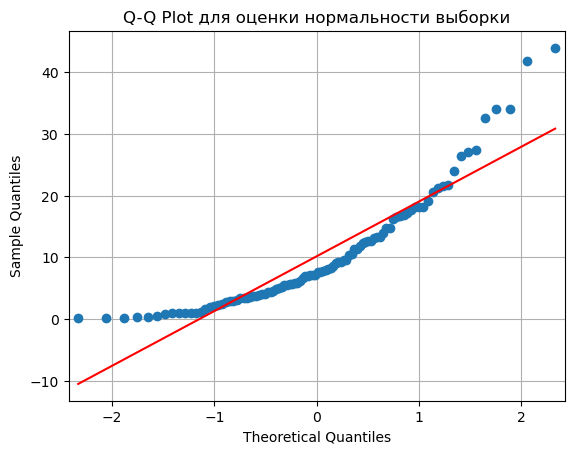

In [4]:
# Задача 4: Изучить распределение времени, необходимого для обслуживания клиентов в кафе, и проверить это распределение на "нормальность".
 - 1. Сгенерируйте генеральную совокупность времени обслуживания клиентов, используя экспоненциальное распределение с параметром scale=10 и размером 1000 с помощью np.random.exponential.
 - 2. Из этой генеральной совокупности извлеките случайную выборку из 100 значений без замены.
 - 3. Визуализируйте распределение выборки с помощью sns.kdeplot и plt.hist, настроив параметры для корректного отображения гистограммы.
 - 4. Используйте Q-Q plot (sm.qqplot) для проверки выборки на "нормальность", используя line='r' для сравнения с нормальным распределением.

import statsmodels.api as sm

# 1. Генерация совокупности
np.random.seed(10)
population = np.random.exponential(scale=10, size=1000)

# 2. Выборка из 100 элементов без замены
sample = np.random.choice(population, size=100, replace=False)

# 3. Гистограмма и KDE
plt.figure(figsize=(10, 5))
sns.kdeplot(sample, fill=True, color='purple', label='Плотность KDE')
plt.hist(sample, bins=20, alpha=0.4, density=True, edgecolor='black', label='Гистограмма')
plt.title('Распределение времени обслуживания клиентов (выборка из экспоненциального распределения)')
plt.xlabel('Время (минуты)')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True)
plt.show()

# 4. Q-Q plot
sm.qqplot(sample, line='r')
plt.title('Q-Q Plot для оценки нормальности выборки')
plt.grid(True)
plt.show()
